> **Experiment F2: Personalised FL, shared encoder, local decoder (FedPer)**
> Guide: [F2 personalised FL](../docs/experiments/F2_personalised_fl.md) · Config: [fed_personalised.yaml](../configs/fed_personalised.yaml)
> Depends on the validated E03 client dataset, F1's federated code and the corrected Arm D baseline.

# Share what generalises, keep what does not
Only the encoder (243 → 133 → 83 → 20) is averaged across the 22 turbines. Each turbine keeps its own decoder, scaler and threshold, so every turbine ends with its own model. Like F1 this is a sequential, in-process Flower simulation, not a deployment or a privacy guarantee.

On Kaggle attach the updated `windturbine-client-bridge.zip` and the saved E03 dataset, and set `WT_CLIENT_DATASET` if more than one dataset is attached. Full defaults: 100 rounds, one local epoch (about the cost of F1's FedAvg branch alone). `WT_F2_ROUNDS` makes an explicit pilot; `WT_F2_SMOKE=1` runs two rounds on a tiny synthetic dataset on CPU, an execution check only. No stored outputs are included.

## 1. Load the exact shared source
Same loader as F1: local checkout, the attached `windturbine-client-bridge.zip`, or an explicit published git revision. `WT_REPO_ROOT` and `WT_REPO_REF` are mutually exclusive, and bundle files are checked against their manifest before any import.

In [1]:
import os, sys, json, zipfile, subprocess, hashlib
from pathlib import Path
from dataclasses import replace
import numpy as np
import pandas as pd

os.environ.setdefault("FLWR_TELEMETRY_ENABLED", "0")
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")
SMOKE = os.environ.get("WT_F2_SMOKE", "0") == "1"
if SMOKE:
    # Small deterministic CPU smoke avoids consuming GPU resources.
    os.environ["CUDA_VISIBLE_DEVICES"] = "-1"
    os.environ.setdefault("TF_NUM_INTRAOP_THREADS", "1")
    os.environ.setdefault("TF_NUM_INTEROP_THREADS", "1")
WORK_ROOT = Path(os.environ.get("WT_WORK_ROOT", "/kaggle/working" if Path("/kaggle/input").exists() else str(Path.cwd())))
WORK_ROOT.mkdir(parents=True, exist_ok=True)
MODULE = Path("src/windturbine/federated/strategies.py")
explicit_root, requested_ref = os.environ.get("WT_REPO_ROOT"), os.environ.get("WT_REPO_REF")
if explicit_root and requested_ref:
    raise ValueError("Choose WT_REPO_ROOT or WT_REPO_REF, not both")
REPO, bundle_sha256, resolved_ref = None, None, None
if explicit_root:
    REPO = Path(explicit_root)
    if not (REPO / MODULE).is_file():
        raise RuntimeError("WT_REPO_ROOT does not contain the client bridge: " + str(REPO))
elif requested_ref:
    REPO = WORK_ROOT / "windturbine-client-bridge-git"
    if not REPO.exists():
        subprocess.run(["git", "clone", "https://github.com/PranavMundhra/Wind-Turbine.git", str(REPO)], check=True)
    subprocess.run(["git", "-C", str(REPO), "checkout", "--detach", requested_ref], check=True)
    resolved_ref = subprocess.run(["git", "-C", str(REPO), "rev-parse", "HEAD"], check=True, capture_output=True, text=True).stdout.strip()
    expected_ref = subprocess.run(["git", "-C", str(REPO), "rev-parse", requested_ref + "^{commit}"], check=True, capture_output=True, text=True).stdout.strip()
    assert resolved_ref == expected_ref, "Requested source revision was not selected"
else:
    candidates = [Path.cwd(), *Path.cwd().parents]
    if Path("/kaggle/input").exists():
        candidates += [p.parent.parent.parent.parent for p in Path("/kaggle/input").rglob("src/windturbine/federated/strategies.py")]
    REPO = next((p for p in candidates if (p / MODULE).is_file()), None)
    if REPO is None and Path("/kaggle/input").exists():
        bundles = list(Path("/kaggle/input").rglob("windturbine-client-bridge.zip"))
        if len(bundles) > 1:
            raise RuntimeError("Attach only one source ZIP, or set WT_REPO_ROOT")
        if bundles:
            bundle_sha256 = hashlib.sha256(bundles[0].read_bytes()).hexdigest()
            target = WORK_ROOT / ("windturbine-source-" + bundle_sha256[:16])
            with zipfile.ZipFile(bundles[0]) as archive:
                names = archive.namelist()
                if len(names) != len(set(names)):
                    raise ValueError("Duplicate paths in source archive")
                for name in names:
                    if "\\" in name or not (target / name).resolve().is_relative_to(target.resolve()):
                        raise ValueError("Unsafe source archive path")
                package_manifest = json.loads(archive.read("bridge_bundle_manifest.json"))
                if package_manifest.get("format_version") != 1 or not isinstance(package_manifest.get("files"), dict):
                    raise ValueError("Unsupported source bundle manifest")
                files = package_manifest["files"]
                if set(names) != set(files) | {"bridge_bundle_manifest.json"}:
                    raise ValueError("Source bundle file list does not match manifest")
                for name, digest in files.items():
                    if hashlib.sha256(archive.read(name)).hexdigest() != digest:
                        raise ValueError("Source bundle hash mismatch: " + name)
                archive.extractall(target)
            REPO = target
if REPO is None or not (REPO / MODULE).is_file():
    raise RuntimeError("Attach windturbine-client-bridge.zip as a Kaggle Dataset (internet off works), "
                       "or attach a source checkout and set WT_REPO_ROOT. Optional internet mode: "
                       "set WT_REPO_REF to a published commit/tag containing src/windturbine/federated/strategies.py.")
# Also verify an already extracted source bundle before importing any package code.
if (REPO / "bridge_bundle_manifest.json").is_file():
    package_manifest = json.loads((REPO / "bridge_bundle_manifest.json").read_text(encoding="utf-8"))
    if package_manifest.get("format_version") != 1:
        raise ValueError("Unsupported extracted source bundle")
    for name, digest in package_manifest["files"].items():
        source_path = (REPO / name).resolve()
        if not source_path.is_relative_to(REPO.resolve()) or hashlib.sha256(source_path.read_bytes()).hexdigest() != digest:
            raise ValueError("Extracted source bundle hash mismatch: " + name)
source_notebooks = [REPO / "notebooks" / name for name in ("13_arm_local_turbine.ipynb", "20_federated_clients.ipynb", "30_fedavg.ipynb",
                                                    "31_fed_personalised.ipynb", "32_fedprox.ipynb", "33_fed_private.ipynb")]
source_files = sorted([*REPO.glob("src/windturbine/**/*.py"), *REPO.glob("configs/*.yaml"),
                       *(p for p in source_notebooks if p.is_file())])
source_hashes = {p.relative_to(REPO).as_posix(): hashlib.sha256(p.read_bytes()).hexdigest() for p in source_files}
SOURCE_IDENTITY = {"source_tree_sha256": hashlib.sha256(json.dumps(source_hashes, sort_keys=True).encode()).hexdigest(),
                   "source_files": source_hashes, "bundle_sha256": bundle_sha256,
                   "requested_git_ref": requested_ref, "resolved_git_commit": resolved_ref}
sys.path.insert(0, str(REPO / "src"))
from windturbine.config import load_config
print("Source:", REPO)
print("Source identity:", json.dumps(SOURCE_IDENTITY, indent=2))

Source: C:\Users\pooja\Desktop\wind turbine\Wind-Turbine
Source identity: {
  "source_tree_sha256": "4cde0e5f61abdad622ca441316b667590511bd69365a5b480164cc2963bcea0a",
  "source_files": {
    "configs/arm_isolated.yaml": "ab352789a22a1d3cfe52d6854ebe095a04e85be89b10e0d51beedd3694ec8af1",
    "configs/arm_local_turbine.yaml": "8db53eded3df967c36e65c4a4d3712438a24581bc2a3abb6fb74520a59261795",
    "configs/arm_pooled.yaml": "c2c70de648928f873760115a5f405f3abb44ca6fe663cb9ee7054cb79c69cfb7",
    "configs/arm_pooled_dedup.yaml": "485e5470df67831de28dde349d7874554857f9cf9b4d0b7ccba1ba717f40b34d",
    "configs/base.yaml": "16668bbdc1a309e8c60d5c8fcc7d831bed2b7fb5b72eb28cfbb19d461a6e7533",
    "configs/clients.yaml": "41cdfee241855f0eb93d228d471b9a8c1224214155b539a25e96e5f0b1121f52",
    "configs/fed_fedavg.yaml": "d538f349350da04a4addcca612adcca1e3fb4e90fec9e699eee1c6a35a1f5be9",
    "configs/fed_fedprox.yaml": "c747ea630eac78e088756a5a736a611ad152153d3544d37d5b7c5954d4a0e57b",
    "configs/

## 2. Check training dependencies
Flower 1.40.0 is the tested aggregation version and TensorFlow 2.21.0 the local validation version. The notebook does not install packages; see the F1 notebook for Kaggle install options. Restart the kernel after changing binary packages.

In [2]:
from importlib import metadata
missing = []
for package in ('flwr', 'tensorflow'):
    try:
        print(package, metadata.version(package))
    except metadata.PackageNotFoundError:
        missing.append(package)
if missing:
    raise RuntimeError("Missing training packages: " + ", ".join(missing) +
                       ". Follow the setup instructions above; this notebook does not install packages automatically.")
if metadata.version("flwr") != "1.40.0":
    raise RuntimeError("Use the tested flwr==1.40.0 aggregation API; restart the kernel after installing it.")
try:
    import tensorflow as tf
    from windturbine.federated import (build_synthetic_clients, load_checkpoint, run_federated, run_preflight,
                                       run_strategy_preflight, summarize_runs)
except ImportError as exc:
    raise RuntimeError("Training dependencies or shared F2-F4 source are unavailable. Attach the updated source bundle.") from exc
print("TensorFlow devices:", tf.config.list_physical_devices())

flwr 1.40.0
tensorflow 2.21.0


TensorFlow devices: [PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU')]


## 3. Resolve the experiment and saved client dataset
The model seed can change; the E03 partitions, scalers and splits are reused unchanged. The decision rule in the guide needs three seeds; one seed is exploratory.

In [3]:
from datetime import datetime, timezone

CFG = load_config(REPO / "configs/base.yaml", REPO / "configs/fed_personalised.yaml")
CFG = replace(CFG, seed=int(os.environ.get("WT_SEED", CFG.seed)))

if os.environ.get("WT_F2_ROUNDS"):
    rounds = int(os.environ["WT_F2_ROUNDS"])
    if rounds < 1:
        raise ValueError("WT_F2_ROUNDS must be positive")
    CFG = replace(CFG, extra={**CFG.extra, "rounds": rounds})
if SMOKE:
    # Synthetic data exists only to exercise the full export/training/readback path.
    CLIENT_ROOT, smoke_fields, smoke_extra = build_synthetic_clients(
        WORK_ROOT / "f2_smoke", REPO / "configs", farm=CFG.farm, source_identity=SOURCE_IDENTITY)
    CFG = replace(CFG, **smoke_fields, extra={**CFG.extra, **smoke_extra})
else:
    if os.environ.get("WT_CLIENT_DATASET"):
        CLIENT_ROOT = Path(os.environ["WT_CLIENT_DATASET"])
    else:
        candidates = list(Path("/kaggle/input").rglob("dataset_manifest.json")) if Path("/kaggle/input").exists() else []
        if len(candidates) != 1:
            raise RuntimeError("Attach the E03 output and set WT_CLIENT_DATASET to its folder containing dataset_manifest.json")
        CLIENT_ROOT = candidates[0].parent

stamp = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S_%fZ")
OUTPUT_ROOT = Path(os.environ.get("WT_F2_OUTPUT_ROOT", str(WORK_ROOT / CFG.output_dir / "F2" / ("" + stamp))))
if Path("/kaggle/input").exists() and not OUTPUT_ROOT.resolve().is_relative_to(Path("/kaggle/working").resolve()):
    raise ValueError("WT_F2_OUTPUT_ROOT must be inside /kaggle/working on Kaggle")
print("Mode:", "SYNTHETIC SMOKE" if SMOKE else "PILOT" if CFG.extra["rounds"] < 100 else "FULL")
print("Saved clients:", CLIENT_ROOT)
print("Run output:", OUTPUT_ROOT)
print("Resolved config:", CFG)

Mode: FULL
Saved clients: D:\wt_work\windturbine_clients
Run output: C:\Users\pooja\Desktop\wind turbine\Wind-Turbine\results\runs\F2\20261026T185302_930994Z
Resolved config: Config(farm='Wind Farm C', dataset_root='data/raw', cache_dir='data/cache', use_avg_only=True, drop_reactive=False, angle_transform=True, max_nan_fraction=0.3, normal_status_ids=(0, 2), wind_speed_cutin=3.0, wind_speed_rated=12.0, power_near_zero_thresh=0.02, hidden_layers=(133, 83, 20, 83, 133), learning_rate=0.0056, use_lr_plateau=False, lr_plateau_factor=0.5, lr_plateau_patience=4, noise_std=0.0, batch_size=64, max_epochs=200, early_stop_patience=10, seed=42, val_fraction=0.15, val_split_mode='blocked', val_block_hours=120, score_quantile=0.99, criticality_threshold=72, beta=0.5, care_weights=(1, 1, 1, 2), arm='fed_personalised', output_dir='results/runs', extra={'framework': 'flwr', 'strategy': 'fedper', 'shared_layers': ['encode1', 'encode2', 'bottleneck'], 'local_layers': ['decode1', 'decode2', 'output'], 'n

## 4. Pass the algorithm and scoring gates
F1's gates (Flower aggregation equals full-batch SGD on unequal clients, server CARE equals direct CARE, TensorFlow checkpoint round trip) run first. The F2-F4 gates then check that secure aggregation equals the row-weighted mean, FedProx with mu=0 equals plain training, DP-SGD with no noise and no effective clipping equals plain training, and the proximal term pulls weights toward the anchor. The run repeats both before training; failure stops it.

In [4]:
preflight = {"fedavg": run_preflight(), "strategy": run_strategy_preflight()}
assert preflight["fedavg"]["passed"] and preflight["strategy"]["passed"], "Preflight gates did not pass"
print(json.dumps(preflight, indent=2, default=str))

W1027 00:23:04.082000 37508 Lib\site-packages\torch\utils\flop_counter.py:29] triton not found; flop counting will not work for triton kernels


{
  "fedavg": {
    "passed": true,
    "sgd_equivalence": {
      "passed": true,
      "rounds": 3,
      "client_rows": [
        3,
        5,
        8
      ],
      "parameter_arrays": 2,
      "max_abs_error": 5.551115123125783e-17,
      "tolerance": 1e-12
    },
    "care_parity": {
      "passed": true,
      "events": 3,
      "results": {
        "Coverage": 1.0,
        "Earliness": 1.0,
        "Reliability": 1.0,
        "Accuracy": 1.0,
        "CARE": 1.0,
        "support": {
          "coverage": 1,
          "earliness": 1,
          "accuracy": 2
        },
        "event_confusion": {
          "tp": 1,
          "fp": 0,
          "fn": 0,
          "tn": 2
        },
        "n_anomaly_events": 1,
        "n_normal_events": 2
      }
    },
    "tensorflow_compatibility": {
      "passed": true,
      "clients": 3,
      "validation_mse": 0.3141769187054198,
      "checkpoint_roundtrip": true,
      "keras_backend": "torch 2.11.0+cu128"
    }
  },
  "strategy":

## 5. Run FedPer
Every round each turbine starts from the broadcast encoder plus its own decoder, trains all layers for one local epoch with a fresh Adam optimizer, and sends back only the encoder. Flower averages the encoders by retained training rows; decoders never leave the turbine. The round with the lowest row-weighted validation MSE of each turbine's own model is selected; prediction scores never select. After the first rounds the run projects its total time and stops early, with a suggested `WT_F2_ROUNDS`, if it would pass `max_hours`.

In [5]:
run_manifest = run_federated(CLIENT_ROOT, OUTPUT_ROOT, CFG, experiment="F2", source_identity=SOURCE_IDENTITY)
(BRANCH, BRANCH_INFO), = run_manifest["branches"].items()
print("Completed branch:", BRANCH, "selected round", BRANCH_INFO["selected_epoch"])

fedper round 1/100: validation MSE 1.19647 (38.7s)
Projected total runtime: 1.32 h (limit 11 h)


fedper round 2/100: validation MSE 1.04948 (35.5s)
Projected total runtime: 1.32 h (limit 11 h)


fedper round 3/100: validation MSE 0.976874 (36.9s)
Projected total runtime: 1.32 h (limit 11 h)


fedper round 4/100: validation MSE 0.953512 (35.6s)


fedper round 5/100: validation MSE 0.943484 (37.3s)


...

fedper round 97/100: validation MSE 0.735687 (36.4s)


fedper round 98/100: validation MSE 0.70677 (38.1s)


fedper round 99/100: validation MSE 0.725187 (37.3s)


fedper round 100/100: validation MSE 0.779643 (38.1s)


Completed branch: fedper selected round 42


## 6. Verify the saved run and reload checkpoints
Do not trust an interrupted export: check the completion marker and every artifact hash before reading results. Each turbine's selected model is reloaded from `selected/client_<id>.npz`.

In [6]:
print("Run artifacts:", OUTPUT_ROOT)
for relative, expected_hash in run_manifest["artifacts"].items():
    artifact = (OUTPUT_ROOT / relative).resolve()
    assert artifact.is_relative_to(OUTPUT_ROOT.resolve()), "Unsafe artifact path"
    assert hashlib.sha256(artifact.read_bytes()).hexdigest() == expected_hash, relative
assert (OUTPUT_ROOT / "COMPLETE").is_file(), "Run was not completely published"
selected = {aid: load_checkpoint(OUTPUT_ROOT / BRANCH_INFO["checkpoint"] / f"client_{aid}.npz")
            for aid in run_manifest["clients"]}
assert all(weights and all(np.isfinite(w).all() for w in weights) for weights in selected.values())
shared = set(run_manifest["shared_parameter_indices"])
first = next(iter(selected.values()))
for index in range(len(first)):
    identical = all(np.array_equal(weights[index], first[index]) for weights in selected.values())
    assert identical == (index in shared or len(selected) == 1), f"Parameter {index} sharing is wrong"
print("Reloaded", len(selected), "client models;", len(shared), "of", len(first), "parameter arrays are shared")

Run artifacts: C:\Users\pooja\Desktop\wind turbine\Wind-Turbine\results\runs\F2\20261026T185302_930994Z


Reloaded

 22 client models; 6 of 12 parameter arrays are shared


## 7. Read the results
Compare with D (each turbine alone) and, when attached via `WT_F1_RUN`, with F1's FedAvg and centralized branches on the same export. The guide's reading: F2 above both C and D beyond noise is the headline; F2 ≈ D means the shared encoder adds nothing at this model size. One seed cannot establish either; keep the dataset hash, selected round and curve with the numbers.

D reference is not comparable to this dataset; no D improvement claim is valid.
        method  selected_round     CARE  Coverage  Earliness  Reliability  Accuracy
     F2 fedper              42 0.625111  0.295712    0.25118     0.662651  0.958006
F1 centralized               2 0.640495  0.316136    0.24376     0.722892  0.959842
     F1 fedavg              26 0.636185  0.352729    0.29421     0.654206  0.939891
 epoch  validation_mse
     0        1.141396
     1        1.196470
     2        1.049485
     3        0.976874
     4        0.953512
     5        0.943484
     6        0.978126
     7        0.920032
     8        0.909153
     9        0.924512
    10        0.999416
    11        0.910550
    12        0.853482
    13        0.931911
    14        0.835123
    15        0.953587
    16        0.841057
    17        0.821291
    18        0.791911
    19        0.762272
    20        0.711290
    21        0.702857
    22        0.765279
    23        0.762922
    24   

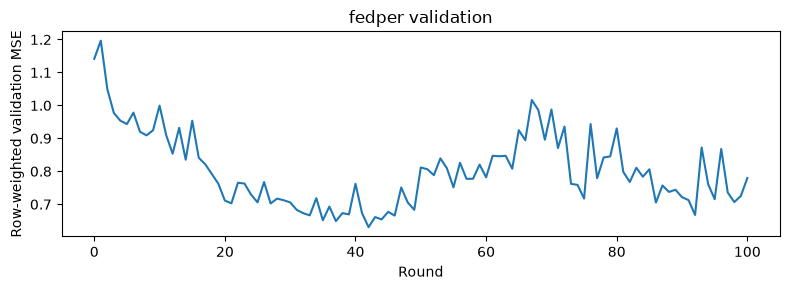

Keep the entire run folder for review: C:\Users\pooja\Desktop\wind turbine\Wind-Turbine\results\runs\F2\20261026T185302_930994Z


In [7]:
reference_hash = "bb2ed3ffc84adbf79bbba624941090acd91831097f427b38b2e20885d4b0b1d1"
dataset_hash = hashlib.sha256((CLIENT_ROOT / "dataset_manifest.json").read_bytes()).hexdigest()
metrics = ["CARE", "Coverage", "Earliness", "Reliability", "Accuracy"]
rows = [{"method": "F2 " + BRANCH, "selected_round": BRANCH_INFO["selected_epoch"],
         **{key: BRANCH_INFO["results"][key] for key in metrics}}]
# Optional: point WT_F1_RUN at an attached, completed F1 run folder to compare on the same table.
if os.environ.get("WT_F1_RUN"):
    f1 = summarize_runs([Path(os.environ["WT_F1_RUN"])])
    if f1.dataset_manifest_sha256.iloc[0] != dataset_hash:
        raise ValueError("WT_F1_RUN used a different dataset")
    rows += [{"method": "F1 " + row.branch, "selected_round": row.selected_epoch,
              **{key: getattr(row, key) for key in metrics}} for row in f1.itertuples()]
comparison = pd.DataFrame(rows)
if dataset_hash == reference_hash and not SMOKE:
    comparison = pd.concat([comparison, pd.DataFrame([{"method": "D (accepted seed 42)", "CARE": 0.639852}])],
                           ignore_index=True)
    print("Matched D dataset; D CARE 0.639852 is a valid single-seed reference.")
else:
    print("D reference is not comparable to this dataset; no D improvement claim is valid.")
print(comparison.to_string(index=False))
curve = pd.read_csv(OUTPUT_ROOT / BRANCH_INFO["rounds"])
print(curve[["epoch", "validation_mse"]].to_string(index=False))
try:
    import matplotlib.pyplot as plt
except ImportError:
    print("Install matplotlib for an inline curve; the full values are shown above.")
else:
    ax = curve.plot(x="epoch", y="validation_mse", title=BRANCH + " validation", figsize=(8, 3), legend=False)
    ax.set_xlabel("Round")
    ax.set_ylabel("Row-weighted validation MSE")
    plt.tight_layout()
    plt.show()
print("Keep the entire run folder for review:", OUTPUT_ROOT)